# Geometra: extracción de cafeterías con Google Places API

**Autor: Aarón Eduardo Arceo Arjona**
___

Notebook complementario del Trabajo Final. Documenta cómo se obtuvo la base de lugares: una malla de celdas de
1 km sobre la mancha urbana de Mérida y una consulta a `places:searchNearby` (Places API New) por celda, con los
tipos `cafe`, `coffee_shop` e `ice_cream_shop`.

**Antes de ejecutar**

- Por defecto solo consulta una muestra de 2 celdas (`EXTRAER_TODO = False`), en menos de un minuto. La malla
  completa son 420 celdas y cientos de llamadas a la API, con costo.
- Requiere una clave de Places API (New); los pasos para obtenerla están en la siguiente celda. Sin clave, el
  notebook corre completo y muestra el resultado original de esas mismas celdas.
- La salida completa, `places_malla_merida.csv`, es la que usa el notebook central (sección 2). Por practicidad ya
  está en la carpeta de datos de Google Drive, que este notebook descarga igual que el central.
- Funciona en Colab o en una instalación local de Python.

### Cómo obtener la clave de Places API (New)

1. Entrar a la consola de Google Cloud (https://console.cloud.google.com) y crear un proyecto nuevo.
2. En *Facturación*, vincular una cuenta de facturación al proyecto (se solicita una tarjeta). Google ofrece un
   número de llamadas gratuitas al mes por tipo de consulta, y la muestra de este notebook cabe en ese margen.
3. En *APIs y servicios > Biblioteca*, buscar **Places API (New)** y habilitarla. No debe confundirse con
   *Places API*, la versión anterior.
4. En *APIs y servicios > Credenciales*, elegir *Crear credenciales > Clave de API* y copiar la clave.
5. Se recomienda editar la clave y, en *Restricciones de API*, limitarla a Places API (New).
6. Guardar la clave fuera del código, con el nombre `PLACES_API_KEY`:
   - En Colab: panel *Secretos* (ícono de llave) > *Agregar secreto nuevo*, y activar el acceso del notebook.
   - En local: un archivo `.env` junto al notebook con la línea `PLACES_API_KEY=...`, o una variable de entorno.

Si no la encuentra, el notebook la pide al ejecutarse sin mostrarla en pantalla; si se deja vacía, se omite la
consulta.

## 0. Configuración y datos

In [1]:
import importlib.util
import subprocess
import sys

PAQUETES = {'geopandas': 'geopandas', 'gdown': 'gdown', 'requests': 'requests', 'dotenv': 'python-dotenv'}
faltantes = [pip for modulo, pip in PAQUETES.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltantes], check=True, capture_output=True)
print('Bibliotecas instaladas en esta sesión:', ', '.join(faltantes) or 'ninguna')

Bibliotecas instaladas en esta sesión: ninguna


In [2]:
# Parámetros -----------------------------------------------------------------
ID_DRIVE = '1WM18VwFvPEIWJGDBrt8Jndqw3WjfoGgk'   # ID de Datos_Geometra.zip en Google Drive
EXTRAER_TODO = False   # True: consulta las 420 celdas de la malla (cientos de llamadas, con costo)
N_CELDAS_CENTRO = 1    # muestra: celdas más cercanas al centro de la ciudad (zona densa)
N_CELDAS_AZAR = 1      # muestra: celdas elegidas al azar
SEMILLA = 0

import json
import os
import time
import warnings
import zipfile
from pathlib import Path

warnings.filterwarnings('ignore')   # avisos de versiones de bibliotecas; no afectan los resultados

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
from shapely.geometry import box

pd.set_option('display.max_columns', None, 'display.width', None, 'display.max_colwidth', 60)

color1, color2, color3, color4, color5 = '#282832', '#77181e', '#a92727', '#c6d6d6', '#dee7e7'   # paleta del proyecto
CRS_M = 'EPSG:32616'   # UTM zona 16N, en metros
CVE_MUN_MERIDA = '31050'
print('Bibliotecas importadas.')

Bibliotecas importadas.


In [3]:
def preparar_datos(carpeta='Datos_Geometra', id_drive=ID_DRIVE):
    """Devuelve la carpeta de datos del proyecto.

    Si la carpeta ya existe junto al notebook se usa tal cual; si no, se descarga el
    archivo comprimido desde Google Drive y se descomprime en el directorio actual.
    """
    ruta = Path(carpeta)
    if not ruta.is_dir():
        import gdown
        archivo = gdown.download(id=id_drive, output=f'{carpeta}.zip', quiet=True)
        with zipfile.ZipFile(archivo) as z:
            z.extractall('.')
    return ruta


def obtener_api_key(nombre='PLACES_API_KEY'):
    """Busca la clave en los Secretos de Colab, en un archivo .env o en una variable de entorno.

    Si no la encuentra, la pide sin mostrarla. Devuelve None si no hay clave.
    """
    try:
        from google.colab import userdata
        return userdata.get(nombre)
    except Exception:
        pass
    try:
        from dotenv import load_dotenv
        load_dotenv()
    except ImportError:
        pass
    if os.getenv(nombre):
        return os.getenv(nombre)
    try:
        from getpass import getpass
        return getpass(f'{nombre} (Enter para omitir): ').strip() or None
    except Exception:
        return None


DATOS = preparar_datos()
SALIDAS = Path('salidas')
SALIDAS.mkdir(exist_ok=True)
API_KEY = obtener_api_key()
print('Clave de Places API disponible:', 'sí' if API_KEY else 'no (se mostrará el resultado original)')

Clave de Places API disponible: no (se mostrará el resultado original)


## 1. Malla de búsqueda

Celdas de 1,000 por 1,000 m sobre el rectángulo que encierra las 541 AGEB urbanas de Mérida. Se conservan las
celdas cuyo círculo de búsqueda (radio de unos 707 m, la mitad de la diagonal, para cubrir la celda completa)
toca la mancha urbana con un margen de 200 m.

In [4]:
agebs = gpd.read_file(DATOS / 'agebs_merida_urbanas.gpkg')
agebs_merida = (agebs[(agebs['cve_mun'] == CVE_MUN_MERIDA) & (agebs['ambito'] == 'U')][['cvegeo', 'geometry']]
                .to_crs(CRS_M).reset_index(drop=True))

CELL_SIZE = 1000.0       # metros
BUFFER_MANCHA_M = 200.0  # margen por ruido de geocodificación

minx, miny, maxx, maxy = agebs_merida.total_bounds
celdas = [box(x0, y0, x0 + CELL_SIZE, y0 + CELL_SIZE)
          for x0 in np.arange(minx, maxx, CELL_SIZE) for y0 in np.arange(miny, maxy, CELL_SIZE)]
malla = gpd.GeoDataFrame({'celda_id': range(len(celdas))}, geometry=celdas, crs=CRS_M)
print(f'Celdas en el rectángulo ({maxx - minx:,.0f} x {maxy - miny:,.0f} m): {len(malla)}')

radio_m = CELL_SIZE / np.sqrt(2)
mancha_urbana = agebs_merida.union_all().buffer(BUFFER_MANCHA_M)
malla = malla[malla.geometry.centroid.buffer(radio_m).intersects(mancha_urbana)].reset_index(drop=True)
print(f'Celdas que tocan la mancha urbana: {len(malla)}')

Celdas en el rectángulo (21,666 x 33,422 m): 748


Celdas que tocan la mancha urbana: 420


Celdas a consultar: 2 (muestra) | celda_id: [359, 394]


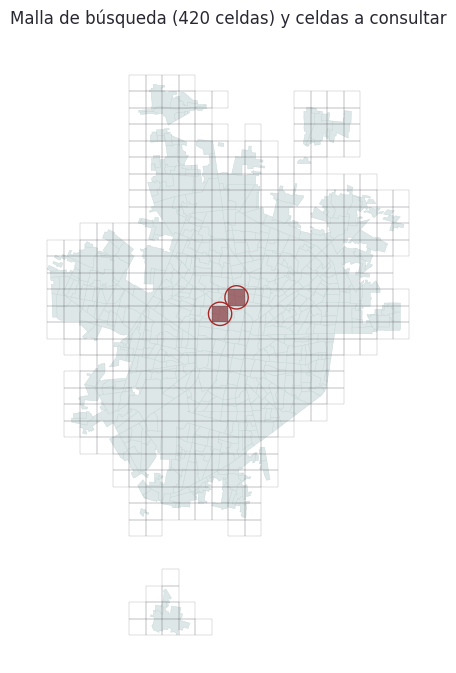

In [5]:
centro_ciudad = agebs_merida.union_all().centroid
distancia = malla.geometry.centroid.distance(centro_ciudad)
cercanas = malla.loc[distancia.nsmallest(N_CELDAS_CENTRO).index]
al_azar = malla.drop(cercanas.index).sample(N_CELDAS_AZAR, random_state=SEMILLA)
muestra = malla if EXTRAER_TODO else pd.concat([cercanas, al_azar])
print(f'Celdas a consultar: {len(muestra)} ({"malla completa" if EXTRAER_TODO else "muestra"}) '
      f'| celda_id: {muestra["celda_id"].tolist()[:10]}')

fig, ax = plt.subplots(figsize=(7, 8))
agebs_merida.plot(ax=ax, color=color5, edgecolor=color4, linewidth=0.3)
malla.boundary.plot(ax=ax, color=color1, linewidth=0.2, alpha=0.5)
muestra.plot(ax=ax, color=color2, alpha=0.6)
gpd.GeoSeries(muestra.geometry.centroid.buffer(radio_m), crs=CRS_M).boundary.plot(ax=ax, color=color3, linewidth=1)
ax.set_title(f'Malla de búsqueda ({len(malla)} celdas) y celdas a consultar', color=color1)
ax.set_axis_off()
plt.show()

## 2. Consulta a Places API (New)

Cada llamada devuelve como máximo 20 lugares. Si una celda llega a ese tope pudo quedar truncada, así que se divide
en 4 cuadrantes que se consultan por separado, hasta dos niveles (1,000 a 500 y a 250 m). Las llamadas se
reintentan ante errores temporales y el avance se guarda para poder reanudar la corrida completa.

In [6]:
PLACES_NEARBY_URL = 'https://places.googleapis.com/v1/places:searchNearby'
FIELD_MASK = ','.join([
    'places.id', 'places.displayName', 'places.formattedAddress', 'places.location', 'places.primaryType',
    'places.types', 'places.rating', 'places.userRatingCount', 'places.businessStatus', 'places.priceLevel',
    'places.editorialSummary', 'places.googleMapsUri', 'places.googleMapsLinks',
])   # solo los campos necesarios: el costo de la llamada depende de los campos pedidos
TIPOS_INCLUIDOS = ['cafe', 'coffee_shop', 'ice_cream_shop']
MAX_RESULT_COUNT = 20
MAX_PROFUNDIDAD_REFINAMIENTO = 2
COLUMNAS_MALLA = ['celda_id', 'place_id', 'nombre_google', 'direccion_google', 'lat_google', 'lon_google',
                  'primary_type', 'types', 'rating', 'n_resenas', 'business_status', 'price_level',
                  'resumen_editorial', 'google_maps_uri', 'google_maps_links']


def buscar_nearby(lat, lon, radio, intentos=3):
    """Lugares de los tipos incluidos dentro de un círculo; reintenta ante errores temporales."""
    headers = {'Content-Type': 'application/json', 'X-Goog-Api-Key': API_KEY, 'X-Goog-FieldMask': FIELD_MASK}
    body = {
        'includedTypes': TIPOS_INCLUIDOS,
        'maxResultCount': MAX_RESULT_COUNT,
        'languageCode': 'es',
        'locationRestriction': {'circle': {'center': {'latitude': lat, 'longitude': lon}, 'radius': radio}},
    }
    for intento in range(intentos):
        resp = requests.post(PLACES_NEARBY_URL, headers=headers, json=body, timeout=15)
        if resp.status_code == 200:
            return resp.json().get('places', [])
        if resp.status_code not in (429, 500, 503):
            break
        time.sleep(2 ** intento)
    try:
        mensaje = resp.json()['error']['message']
    except Exception:
        mensaje = resp.text[:200]
    raise RuntimeError(f'Places API respondió {resp.status_code}: {mensaje}')


def subdividir_celda(geom):
    """Divide un cuadrado en 4 cuadrantes iguales."""
    minx, miny, maxx, maxy = geom.bounds
    midx, midy = (minx + maxx) / 2, (miny + maxy) / 2
    return [box(minx, miny, midx, midy), box(midx, miny, maxx, midy),
            box(minx, midy, midx, maxy), box(midx, midy, maxx, maxy)]


def buscar_celda_recursivo(geom, profundidad=0):
    """Consulta el círculo que cubre la celda; si llega al tope de resultados, la subdivide y repite."""
    centro = gpd.GeoSeries([geom.centroid], crs=CRS_M).to_crs('EPSG:4326').iloc[0]
    lado = geom.bounds[2] - geom.bounds[0]
    lugares = buscar_nearby(centro.y, centro.x, lado / np.sqrt(2))
    if len(lugares) < MAX_RESULT_COUNT or profundidad >= MAX_PROFUNDIDAD_REFINAMIENTO:
        return lugares
    print(f'  celda de {lado:.0f} m en el tope de {MAX_RESULT_COUNT}: se subdivide (nivel {profundidad + 1})')
    resultado = []
    for sub in subdividir_celda(geom):
        resultado.extend(buscar_celda_recursivo(sub, profundidad + 1))
    return resultado


def a_fila(celda_id, lugar):
    """Convierte un lugar de la respuesta de la API en una fila de la tabla de salida."""
    loc = lugar.get('location') or {}
    links = lugar.get('googleMapsLinks')
    return {
        'celda_id': celda_id, 'place_id': lugar.get('id'),
        'nombre_google': (lugar.get('displayName') or {}).get('text'),
        'direccion_google': lugar.get('formattedAddress'),
        'lat_google': loc.get('latitude'), 'lon_google': loc.get('longitude'),
        'primary_type': lugar.get('primaryType'), 'types': ','.join(lugar.get('types', [])),
        'rating': lugar.get('rating'), 'n_resenas': lugar.get('userRatingCount'),
        'business_status': lugar.get('businessStatus'), 'price_level': lugar.get('priceLevel'),
        'resumen_editorial': (lugar.get('editorialSummary') or {}).get('text'),
        'google_maps_uri': lugar.get('googleMapsUri'),
        'google_maps_links': json.dumps(links) if links else None,
    }


def procesar_malla(celdas_df, ruta_salida, pausa=0.05):
    """Consulta cada celda pendiente y va guardando en `ruta_salida`; si el archivo existe, retoma el avance."""
    if ruta_salida.exists():
        resultados = pd.read_csv(ruta_salida, dtype={'celda_id': str})
    else:
        resultados = pd.DataFrame(columns=COLUMNAS_MALLA)
    pendientes = celdas_df[~celdas_df['celda_id'].astype(str).isin(set(resultados['celda_id']))]
    print(f'Celdas pendientes: {len(pendientes)} de {len(celdas_df)}')

    filas = []
    for n, (_, celda) in enumerate(pendientes.iterrows(), start=1):
        celda_id = str(celda['celda_id'])
        lugares = buscar_celda_recursivo(celda['geometry'])
        filas.extend([a_fila(celda_id, l) for l in lugares] or [{'celda_id': celda_id, 'place_id': None}])
        print(f'[{n}/{len(pendientes)}] celda {celda_id}: {len(lugares)} lugares')
        time.sleep(pausa)
        if len(filas) >= 50 or n == len(pendientes):
            resultados = pd.concat([resultados, pd.DataFrame(filas)], ignore_index=True)
            resultados.to_csv(ruta_salida, index=False)
            filas = []
    return resultados

In [7]:
original = pd.read_csv(DATOS / 'places_malla_merida.csv', dtype={'celda_id': str, 'place_id': str})
ids_muestra = muestra['celda_id'].astype(str)
RUTA_SALIDA = SALIDAS / ('places_malla_merida.csv' if EXTRAER_TODO else 'places_malla_muestra.csv')

resultado = None
if API_KEY:
    if not EXTRAER_TODO:
        RUTA_SALIDA.unlink(missing_ok=True)   # la muestra se consulta de nuevo en cada ejecución
    try:
        resultado = procesar_malla(muestra, RUTA_SALIDA)
        print(f'Guardado en {RUTA_SALIDA.as_posix()}')
    except RuntimeError as e:
        print(f'No se pudo consultar la API. {e}')
if resultado is None:
    resultado = original[original['celda_id'].isin(ids_muestra)]
    print('Se muestra el resultado original de estas celdas (places_malla_merida.csv en Drive).')

Se muestra el resultado original de estas celdas (places_malla_merida.csv en Drive).


## 3. Resultado

Una celda puede repetir lugares de sus vecinas por el traslape de los círculos. Si se consultó la API, se compara
con el resultado original (septiembre de 2026); pueden diferir porque Google actualiza sus fichas.

In [8]:
encontrados = resultado[resultado['place_id'].notna()]
unicos = encontrados.groupby('place_id', as_index=False).first()
ids_original = set(original.loc[original['celda_id'].isin(ids_muestra), 'place_id'].dropna())
print(f'Filas: {len(resultado)} | lugares encontrados (con repetidos): {len(encontrados)} | únicos: {len(unicos)}')
print(f'Únicos en el resultado original de estas celdas: {len(ids_original)} '
      f'| en común: {len(set(unicos["place_id"]) & ids_original)}')
print('\nTipo principal:')
print(unicos['primary_type'].value_counts().head(10))
unicos.sort_values('n_resenas', ascending=False)[
    ['nombre_google', 'primary_type', 'rating', 'n_resenas', 'business_status', 'price_level']].head(15)

Filas: 47 | lugares encontrados (con repetidos): 47 | únicos: 39
Únicos en el resultado original de estas celdas: 39 | en común: 39

Tipo principal:
primary_type
coffee_shop          25
cafe                  6
ice_cream_shop        2
cafeteria             2
brunch_restaurant     1
restaurant            1
dessert_shop          1
bakery                1
Name: count, dtype: int64


,nombre_google,primary_type,rating,n_resenas,business_status,price_level
2,Dunkin' Buenavista,coffee_shop,4.3,2368.0,OPERATIONAL,PRICE_LEVEL_MODERATE
19,Flores Café,cafe,4.7,1140.0,OPERATIONAL,PRICE_LEVEL_MODERATE
4,Don Massu,coffee_shop,4.7,583.0,OPERATIONAL,PRICE_LEVEL_MODERATE
34,Catalina Bakery,bakery,4.5,493.0,OPERATIONAL,PRICE_LEVEL_MODERATE
20,Calidia,restaurant,4.7,335.0,OPERATIONAL,PRICE_LEVEL_MODERATE
6,Artesanal Bakery Coffee Shop,coffee_shop,4.5,220.0,OPERATIONAL,PRICE_LEVEL_MODERATE
22,Cafeto Supremo,coffee_shop,4.7,205.0,OPERATIONAL,PRICE_LEVEL_MODERATE
8,Browniques,coffee_shop,4.8,88.0,OPERATIONAL,PRICE_LEVEL_MODERATE
12,Marshé Mercado & Healthy Bar,coffee_shop,4.9,77.0,OPERATIONAL,PRICE_LEVEL_MODERATE
38,Lola´s Lunch,coffee_shop,4.8,75.0,OPERATIONAL,PRICE_LEVEL_MODERATE


La depuración de esta base (ubicación, duplicados, estatus y relevancia del tipo) está en la sección 2 del notebook
central, que parte del archivo completo `places_malla_merida.csv`.